# ¿Cuántos símbolos hacen falta para decidir?
## Monitoreo secuencial de traslape espectral en señales ópticas IQ con Calibración de Creencias y Parada Óptima por SARSA

**Proyecto final — Sistemas de Decisión Autónoma bajo Incertidumbre**  
**Ruta metodológica:** Inferencia bayesiana secuencial (verosimilitud atemperada) + Diagnóstico de calibración (Brier y diagrama de confiabilidad) + Políticas de parada secuencial (SARSA multi-semilla vs. ventana fija vs. umbral de confianza)  
**Escenario principal:** 32 GBd, back-to-back (`32G_B2B`)

Este notebook documenta la formulación, implementación y validación experimental del sistema de monitoreo espectral autónomo. El objetivo es resolver el problema de parada óptima: decidir secuencialmente cuántos bloques de símbolos observar antes de declarar la presencia ($z=1$) o ausencia ($z=0$) de traslape espectral, minimizando la suma del costo de observación y los costos de decisión errónea.


## Mapa del notebook

1. **Entorno y configuración:** Carga de módulos, lectura de configuración YAML y definición de costos de decisión.
2. **Parámetros y ampliación de separaciones:** Selección balanceada de separaciones alrededor de la frontera geométrica ($35.2$ GHz): `[34.0, 34.5, 35.0, 35.5, 36.0, 37.5] GHz`.
3. **Inventario de datos y consistencia:** Extracción y verificación de condiciones compartidas entre canciones.
4. **Inspección de IQ y Feature EVM:** Análisis físico de la constelación 16-QAM y extracción del Error Vector Magnitude (EVM) respecto al símbolo más cercano como feature discriminativa de traslape.
5. **Partición estricta por adquisiciones:** Asignación independiente de canciones (`song1` KDE, `song2` SARSA train, `song3` validación, `song4` prueba) garantizando cero fuga de información.
6. **Ajuste del banco KDE por condición:** Densidades 2D sobre `song1` y prior uniforme por clase.
7. **Aumento de episodios sin cruce:** Extracción de múltiples ventanas desplazadas por captura para enriquecer la experiencia de aprendizaje.
8. **Diagnóstico y Calibración del posterior antes de SARSA:**
   - 8.1 Diagnóstico de saturación y sobreconfianza del posterior original (Brier Score y diagrama de confiabilidad).
   - 8.2 Búsqueda en grilla / validación cruzada de $h$ y verosimilitud atemperada (factor de tamaño efectivo).
   - 8.3 Trazas de creencia calibrada a lo largo del tiempo.
9. **MDP aproximado:** Espacio de estados $(k, 	ext{bin}(b_k))$, acciones y recompensas de observación y decisión.
10. **Entrenamiento de SARSA multi-semilla:** Aprendizaje on-policy con reporte de media y dispersión ($\pm 1	ext{ std}$) sobre múltiples semillas.
11. **Políticas de referencia:** Calibración de ventana fija y umbral de confianza bayesiano en validación (`song3`).
12. **Evaluación rigurosa en `song4`:** Comparación de políticas con estadísticas agregadas (media ± std).
13. **Comparación a costo y error equivalentes:** Análisis de la frontera de Pareto (error vs latencia y costo total esperado).
14. **Lectura crítica y artefactos:** Síntesis técnica y próximos pasos.


## 1. Entorno y configuración

Se importan las bibliotecas numéricas y los módulos estructurados del paquete `src/`: inventario, cargador de adquisiciones, banco de densidades KDE y actualización bayesiana secuencial.


In [21]:
from pathlib import Path
import sys
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

# Permite ejecutar el notebook desde la raíz del repo o desde notebooks/.
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / "src").is_dir() and (p / "configs/experiment.yaml").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("No encuentro la raíz del proyecto (src/ y configs/experiment.yaml).")

sys.path.insert(0, str(ROOT))
from src.data.inventory import InventoryConfig, build_inventory, summarize
from src.data.loader import load_capture, load_inventory, split_into_blocks
from src.kde.bank import build_bank, ConditionKDE, KDEBank
from src.bayes.update import (
    build_prior, posterior_from_loglik, overlap_prob,
    compute_brier_score, reliability_curve, accumulate_loglik
)

DATA_DIR = ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

SEED = 7
np.random.seed(SEED)
print("Raíz del proyecto:", ROOT)
print("Carpeta de datos procesados:", PROCESSED_DIR)


Raíz del proyecto: /home/oagr/Documentos/UdeA/Semestre 2026-2/SDAI/Proyecto Final
Carpeta de datos procesados: /home/oagr/Documentos/UdeA/Semestre 2026-2/SDAI/Proyecto Final/data/processed


## 2. Parámetros del experimento y ampliación de separaciones

### Ampliación del conjunto de separaciones
En lugar de limitarse a sólo dos separaciones ($35.0$ y $35.5$ GHz), ampliamos a un conjunto balanceado alrededor de la frontera física nominal:
$$B_{nom} = R_s (1 + 
ho) = 32(1 + 0.1) = 35.2\;\mathrm{GHz}$$

- **Clase con traslape ($z=1$, $\mathrm{ChSp} < 35.2\;\mathrm{GHz}$):** $34.0$, $34.5$ y $35.0\;\mathrm{GHz}$ (distintos grados de interferencia inter-canal).
- **Clase sin traslape ($z=0$, $\mathrm{ChSp} > 35.2\;\mathrm{GHz}$):** $35.5$, $36.0$ y $37.5\;\mathrm{GHz}$ (márgenes crecientes de guarda).

Esto permite evaluar el monitor ante diferentes niveles de solape y OSNR, enriqueciendo sustancialmente el problema de decisión.


In [22]:
with open(ROOT / "configs/experiment.yaml", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)

data_cfg = cfg["data"]
RS_GBAUD = float(data_cfg["rs_gbaud"])
ROLLOFF = float(data_cfg["rolloff"])
BOUNDARY_GHZ = RS_GBAUD * (1.0 + ROLLOFF)  # 35.2 GHz

# Parámetros del bloque y horizonte secuencial
BLOCK_SIZE = 100         # m símbolos por bloque
MAX_BLOCKS = 10          # horizonte máximo de decisión: 10 bloques (1000 símbolos)
KDE_CENTERS = 150        # centros por condición para el banco KDE
BANDWIDTH = 0.20         # ancho de banda h calibrado (mayor suavizado para evitar colapso de densidad)
TEMPERATURE = 50.0       # factor de atemperamiento / tamaño efectivo para mitigar sobreconfianza
N_SLICES_PER_CAPTURE = 5 # ventanas desplazadas no solapadas por captura para multiplicar episodios

# Separaciones seleccionadas (3 traslapadas, 3 sin traslape)
FOCUS_CHSP = [34.0, 34.5, 35.0, 35.5, 36.0, 37.5]

# Costos ilustrativos para el trade-off de decisión
C_FN = 10.0       # Costo de falso negativo (declarar sin traslape cuando sí hay)
C_FP = 5.0        # Costo de falso positivo (declarar traslape cuando no hay)
C_OBS = 0.05      # Costo por bloque observado adicional
gamma = 1.0       # Horizonte finito: sin descuento temporal

print(f"Ancho nominal (frontera): {BOUNDARY_GHZ:.1f} GHz")
print(f"Separaciones de estudio: {FOCUS_CHSP}")
print(f"Bloque: {BLOCK_SIZE} símbolos; Horizonte: {MAX_BLOCKS} bloques ({BLOCK_SIZE * MAX_BLOCKS} símbolos)")
print(f"KDE: {KDE_CENTERS} centros, h={BANDWIDTH}, Temperatura={TEMPERATURE}")
print(f"Costos: C_FN={C_FN}, C_FP={C_FP}, C_OBS={C_OBS}")


Ancho nominal (frontera): 35.2 GHz
Separaciones de estudio: [34.0, 34.5, 35.0, 35.5, 36.0, 37.5]
Bloque: 100 símbolos; Horizonte: 10 bloques (1000 símbolos)
KDE: 150 centros, h=0.2, Temperatura=50.0
Costos: C_FN=10.0, C_FP=5.0, C_OBS=0.05


## 3. Inventario de los archivos y condiciones compartidas

Construimos el inventario completo y filtramos las condiciones que tienen réplica en las 4 canciones (`song1` a `song4`). Así garantizamos que las condiciones evaluadas en prueba estén presentes en el banco de entrenamiento.


In [23]:
inventory_cfg = InventoryConfig.from_yaml(ROOT / "configs/experiment.yaml")
inv = build_inventory(inventory_cfg)
inv.to_csv(PROCESSED_DIR / "inventory.csv", index=False)

def song_from_capture_id(capture_id):
    name = str(capture_id).rsplit("/", 1)[-1]
    return name.split("_", 1)[0]

inv["song"] = inv["capture_id"].map(song_from_capture_id)
focus_inv = inv[
    inv["scenario"].eq("32G_B2B")
    & inv["chsp_ghz"].isin(FOCUS_CHSP)
    & inv["label_geometrica"].notna()
].copy()

# Encontrar condiciones (ChSp, OSNR) exactamente compartidas por las cuatro canciones
required_songs = ["song1", "song2", "song3", "song4"]
condition_sets = {
    song: set(zip(
        focus_inv.loc[focus_inv["song"].eq(song), "chsp_ghz"].astype(float),
        focus_inv.loc[focus_inv["song"].eq(song), "osnr_db"].round(2),
    ))
    for song in required_songs
}
common_conditions = set.intersection(*(condition_sets[song] for song in required_songs))
focus_inv = focus_inv[focus_inv.apply(
    lambda r: (float(r["chsp_ghz"]), round(float(r["osnr_db"]), 2)) in common_conditions,
    axis=1
)].copy()

counts = (focus_inv.groupby(["chsp_ghz", "song"], observed=True)
          .size().unstack(fill_value=0).sort_index())
display(counts)
print(f"Total de condiciones únicas (ChSp, OSNR) compartidas por las 4 canciones: {len(common_conditions)}")
print(f"Total de adquisiciones en el dataset balanceado: {len(focus_inv)}")


song,song1,song2,song3,song4
chsp_ghz,,,,
34.0,11,11,11,11
34.5,10,10,10,10
35.0,6,6,6,6
35.5,12,12,12,12
36.0,11,11,11,11
37.5,8,8,8,8


Total de condiciones únicas (ChSp, OSNR) compartidas por las 4 canciones: 58
Total de adquisiciones en el dataset balanceado: 232


## 4. Inspección de IQ y Feature EVM respecto al símbolo más cercano

### 4.1 Constelación RX cruda
En señales ópticas coherentes con modulación 16-QAM, la constelación normalizada teórica contiene 16 puntos distribuidos en un reticulado bidimensional con coordenadas $I, Q \in \{\pm 1, \pm 3\}/\sqrt{10}$.


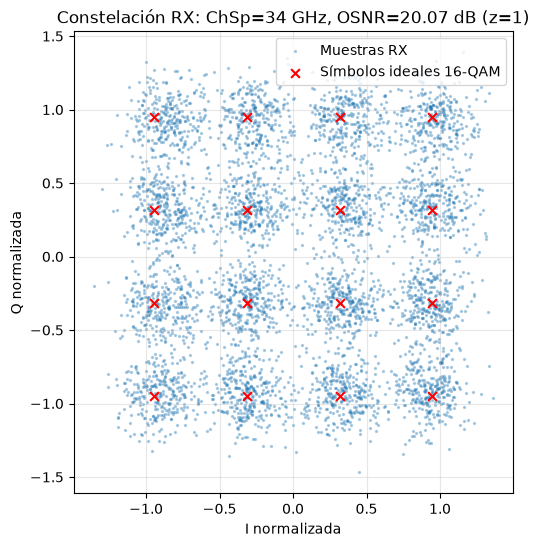

In [24]:
example_row = focus_inv[focus_inv["label_geometrica"] == 1].iloc[0]
example_capture = load_capture(example_row)
n_show = min(5000, len(example_capture.y))
y_show = example_capture.y[:n_show]

# Reticulado teórico 16-QAM normalizado
grid_1d = np.array([-3.0, -1.0, 1.0, 3.0]) / np.sqrt(10.0)
constellation = np.array([i + 1j * q for i in grid_1d for q in grid_1d])

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_show.real, y_show.imag, s=2, alpha=0.3, color="tab:blue", label="Muestras RX")
ax.scatter(constellation.real, constellation.imag, s=40, color="red", marker="x", label="Símbolos ideales 16-QAM")
ax.set(title=f"Constelación RX: ChSp={example_capture.chsp_ghz:g} GHz, OSNR={example_capture.osnr_db:g} dB (z={example_capture.label})",
       xlabel="I normalizada", ylabel="Q normalizada")
ax.set_aspect("equal")
ax.grid(alpha=0.3)
ax.legend(loc="upper right")
plt.show()


### 4.2 Feature más informativa para el traslape: Error Vector Magnitude (EVM) por bloque

#### Justificación física
El plano $IQ$ crudo dispersa los símbolos en 16 nubes aisladas. Cuando la KDE 2D opera directamente sobre $(I, Q)$, gran parte de la varianza estimada refleja la posición aleatoria de cada símbolo dentro de la constelación y el ruido térmico local, en lugar de la firma específica del traslape.

Físicamente, el traslape espectral introduce interferencia inter-canal (crosstalk). Esta interferencia añade una perturbación estocástica de cola pesada que ensancha las nubes y desplaza las muestras respecto al símbolo transmitido. Por tanto, la métrica directa de degradación es la distancia al símbolo más cercano del reticulado:
$$e_i = \min_{s \in \mathcal{C}_{16}} |y_i - s|$$

Para un bloque de $m$ símbolos, el **EVM del bloque** (Error Vector Magnitude) se define como:
$$\mathrm{EVM}_{\mathrm{bloque}} = \sqrt{\frac{1}{m} \sum_{i=1}^m e_i^2}$$

A continuación calculamos y comparamos el EVM para capturas con y sin traslape a lo largo de diversos niveles de OSNR.


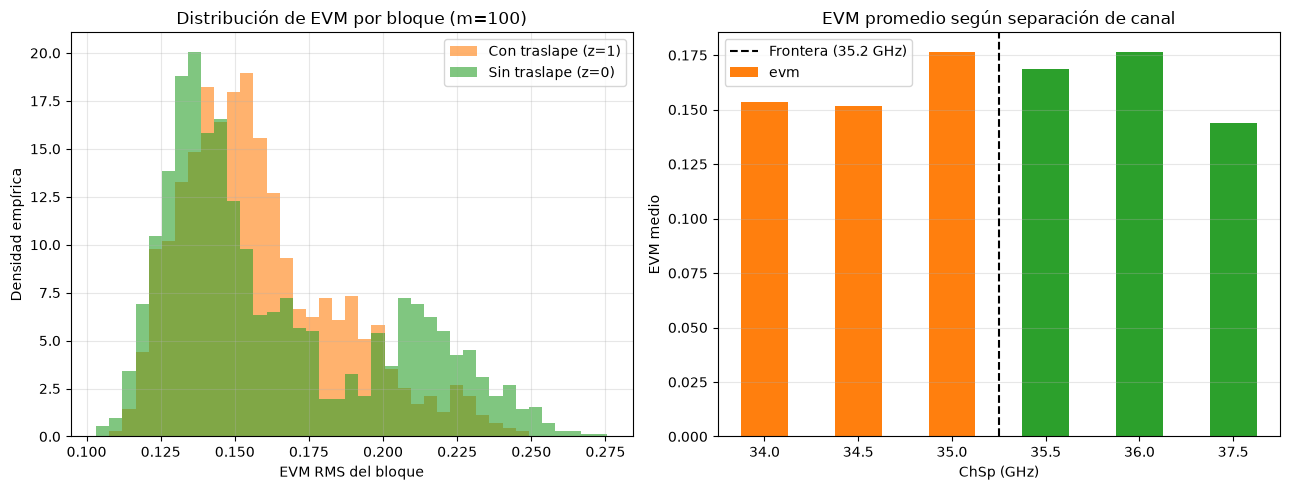

Resumen de EVM por clase:


,count,mean,std,min,25%,50%,75%,max
z,,,,,,,,
0,1600.0,0.1633,0.0372,0.1032,0.1346,0.1496,0.1951,0.2757
1,1600.0,0.1587,0.0267,0.1099,0.1392,0.1537,0.1738,0.2472


In [25]:
def compute_evm_errors(y):
    """Calcula la distancia de cada muestra al símbolo 16-QAM más cercano."""
    return np.min(np.abs(y[:, None] - constellation[None, :]), axis=1)

def compute_block_evm(y, block_size=100):
    """Calcula el EVM RMS por bloques de m símbolos."""
    n_blocks = len(y) // block_size
    evm_blocks = []
    for i in range(n_blocks):
        blk = y[i * block_size : (i + 1) * block_size]
        errs = compute_evm_errors(blk)
        evm_blocks.append(np.sqrt(np.mean(errs ** 2)))
    return np.array(evm_blocks)

# Comparar distribución de EVM entre clases sobre una muestra de capturas
evm_records = []
for _, row in focus_inv.sample(min(80, len(focus_inv)), random_state=SEED).iterrows():
    cap = load_capture(row)
    b_evm = compute_block_evm(cap.y[:4000], block_size=BLOCK_SIZE)
    for val in b_evm:
        evm_records.append({
            "chsp_ghz": row["chsp_ghz"],
            "osnr_db": row["osnr_db"],
            "z": int(row["label_geometrica"]),
            "evm": val
        })

df_evm_sample = pd.DataFrame(evm_records)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Histograma de EVM por clase
ax = axes[0]
bins = np.linspace(df_evm_sample["evm"].min(), df_evm_sample["evm"].max(), 40)
ax.hist(df_evm_sample[df_evm_sample["z"] == 1]["evm"], bins=bins, alpha=0.6, density=True,
        color="tab:orange", label="Con traslape (z=1)")
ax.hist(df_evm_sample[df_evm_sample["z"] == 0]["evm"], bins=bins, alpha=0.6, density=True,
        color="tab:green", label="Sin traslape (z=0)")
ax.set(title="Distribución de EVM por bloque (m=100)", xlabel="EVM RMS del bloque", ylabel="Densidad empírica")
ax.grid(alpha=0.3)
ax.legend()

# EVM medio vs ChSp
ax = axes[1]
evm_by_chsp = df_evm_sample.groupby("chsp_ghz")["evm"].mean()
colors = ["tab:orange" if c < BOUNDARY_GHZ else "tab:green" for c in evm_by_chsp.index]
evm_by_chsp.plot.bar(ax=ax, color=colors, rot=0)
ax.axvline(2.5, color="black", linestyle="--", label=f"Frontera ({BOUNDARY_GHZ:.1f} GHz)")
ax.set(title="EVM promedio según separación de canal", xlabel="ChSp (GHz)", ylabel="EVM medio")
ax.grid(axis="y", alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

print("Resumen de EVM por clase:")
display(df_evm_sample.groupby("z")["evm"].describe().round(4))


## 5. Partición estricta por adquisiciones completas

Para evitar cualquier forma de memorización o fuga de datos:
1. `song1`: Ajuste exclusivo del banco KDE por condición.
2. `song2`: Entrenamiento de la política de parada con SARSA.
3. `song3`: Validación cruzada, selección de hiperparámetros ($h$, $T$, umbrales).
4. `song4`: Evaluación final y prueba congelada.

> **Regla de higiene de partición:** Toda ventana, bloque o trayectoria derivada de una captura queda estrictamente confinada a la partición de dicha captura. Nunca se mezclan fragmentos de una captura entre particiones.


In [26]:
train_kde = focus_inv[focus_inv["song"].eq("song1")].copy()
train_policy = focus_inv[focus_inv["song"].eq("song2")].copy()
validation = focus_inv[focus_inv["song"].eq("song3")].copy()
test = focus_inv[focus_inv["song"].eq("song4")].copy()

split_summary = pd.DataFrame({
    "Partición": ["KDE train (song1)", "SARSA train (song2)", "Validación (song3)", "Prueba (song4)"],
    "Capturas": [len(train_kde), len(train_policy), len(validation), len(test)],
    "Traslape (z=1)": [
        (train_kde["label_geometrica"] == 1).sum(),
        (train_policy["label_geometrica"] == 1).sum(),
        (validation["label_geometrica"] == 1).sum(),
        (test["label_geometrica"] == 1).sum()
    ],
    "Sin traslape (z=0)": [
        (train_kde["label_geometrica"] == 0).sum(),
        (train_policy["label_geometrica"] == 0).sum(),
        (validation["label_geometrica"] == 0).sum(),
        (test["label_geometrica"] == 0).sum()
    ]
})
display(split_summary)
assert all(len(p) > 0 for p in [train_kde, train_policy, validation, test]), "Error en particiones." 


,Partición,Capturas,Traslape (z=1),Sin traslape (z=0)
0,KDE train (song1),58,27,31
1,SARSA train (song2),58,27,31
2,Validación (song3),58,27,31
3,Prueba (song4),58,27,31


## 6. Ajustar el banco KDE por condición (`song1`)

Ajustamos un `ConditionKDE` para cada tupla $c = (\mathrm{ChSp}, \mathrm{OSNR})$ utilizando únicamente las señales de `song1`. A continuación, definimos el prior uniforme por clase (50 % a $z=1$ y 50 % a $z=0$) para evitar cualquier sesgo por desbalance en el número de condiciones registradas.


In [27]:
labels = {}
for _, row in focus_inv.drop_duplicates(["chsp_ghz", "osnr_db"]).iterrows():
    labels[(float(row["chsp_ghz"]), float(row["osnr_db"]))] = int(row["label_geometrica"])

bank = build_bank(
    inventory=inv,
    train_capture_ids=train_kde["capture_id"].tolist(),
    bandwidth=BANDWIDTH,
    subsample=KDE_CENTERS,
    seed=SEED,
)
print("Condiciones KDE en el banco:", len(bank.keys()))

prior = build_prior(bank, labels, prior_class=0.5)
print(f"Suma total del prior: {sum(prior.values()):.4f}")
print(f"Prior total de traslape P(z=1): {sum(p for c, p in prior.items() if labels.get(c) == 1):.4f}")
print(f"Prior total sin traslape P(z=0): {sum(p for c, p in prior.items() if labels.get(c) == 0):.4f}")


KDE por condición:   0%|          | 0/58 [00:00<?, ?it/s]

KDE por condición: 100%|██████████| 58/58 [00:00<00:00, 140.50it/s]

Condiciones KDE en el banco: 58
Suma total del prior: 1.0000
Prior total de traslape P(z=1): 0.5000
Prior total sin traslape P(z=0): 0.5000


## 7. Aumento de episodios: Ventanas desplazadas sin mezclar capturas

Cada archivo de captura contiene $\sim 39{,}500$ símbolos. Un episodio de parada tiene un horizonte de $MAX\_BLOCKS = 10$ bloques ($1{,}000$ símbolos). 

En lugar de extraer una sola trayectoria por archivo, extraemos $N_{slices} = 5$ segmentos no solapados de distintas partes de la captura (por ejemplo, índices $0..1000$, $1000..2000$, etc.). Para acelerar el cálculo, evaluamos la matriz de log-densidades $\mathcal{L} \in \mathbb{R}^{N \times C}$ de forma vectorizada por captura y luego calculamos las actualizaciones bayesianas de cada segmento.


In [28]:
keys = list(bank.keys())
n_cond = len(keys)

def generate_partition_episodes(df_partition, bank, prior, labels,
                                n_slices=N_SLICES_PER_CAPTURE,
                                block_size=BLOCK_SIZE, max_blocks=MAX_BLOCKS,
                                temperature=TEMPERATURE):
    """Genera episodios independientes por ventanas desplazadas sin cruzar particiones."""
    episodes = []
    ep_len = block_size * max_blocks
    total_needed = n_slices * ep_len

    for _, row in df_partition.iterrows():
        cap = load_capture(row)
        z = int(row["label_geometrica"])
        y = cap.y
        n_available = len(y)
        if n_available < ep_len:
            continue
        
        n_extract = min(n_slices, n_available // ep_len)
        syms_to_eval = n_extract * ep_len
        
        # Evaluación vectorizada de log f_c(y) para todos los símbolos requeridos
        L = np.empty((syms_to_eval, n_cond), dtype=np.float64)
        for j, cond in enumerate(bank.conditions.values()):
            L[:, j] = cond.log_pdf(y[:syms_to_eval])
            
        # Generar cada episodio a partir de su segmento disjunto
        for s in range(n_extract):
            start = s * ep_len
            end = start + ep_len
            L_ep = L[start:end]
            
            loglik = {k: 0.0 for k in keys}
            posterior0 = {k: prior[k] for k in keys if prior[k] > 0}
            beliefs = [overlap_prob(posterior0, labels)]
            
            for b_idx in range(max_blocks):
                blk_L = L_ep[b_idx * block_size : (b_idx + 1) * block_size]
                # Verosimilitud atemperada: dividida por factor de temperatura
                step = blk_L.sum(axis=0) / float(temperature)
                for j, k in enumerate(keys):
                    loglik[k] += float(step[j])
                post = posterior_from_loglik(loglik, prior)
                beliefs.append(overlap_prob(post, labels))
                
            episodes.append({
                "capture_id": row["capture_id"],
                "slice_idx": s,
                "z": z,
                "beliefs": np.asarray(beliefs, dtype=float),
                "blocks_available": max_blocks,
                "symbols_per_block": block_size,
            })
            
    return episodes

train_episodes = generate_partition_episodes(train_policy, bank, prior, labels)
val_episodes = generate_partition_episodes(validation, bank, prior, labels)
test_episodes = generate_partition_episodes(test, bank, prior, labels)

print(f"Episodios generados — Train (song2): {len(train_episodes)}")
print(f"Episodios generados — Validación (song3): {len(val_episodes)}")
print(f"Episodios generados — Prueba (song4): {len(test_episodes)}")
print(f"Longitud de trayectoria de creencias por episodio: {len(train_episodes[0]['beliefs'])} (incluye prior)")


Episodios generados — Train (song2): 290
Episodios generados — Validación (song3): 290
Episodios generados — Prueba (song4): 290
Longitud de trayectoria de creencias por episodio: 11 (incluye prior)


## 8. Calibración del posterior antes de SARSA

### 8.1 Diagnóstico crítico: ¿Por qué la saturación destruye el estado de SARSA?

En el modelado bayesiano secuencial ingenuo con bloques grandes ($m=100$ o $m=1000$ símbolos) y un ancho de banda pequeño ($h=0.05$), la log-verosimilitud acumulada es la suma de cientos o miles de términos. Debido a pequeñas imperfecciones en el modelo KDE o correlación temporal entre símbolos ópticos, la diferencia de log-verosimilitud entre condiciones crece desproporcionadamente en un solo bloque.

**Efecto de saturación:**
$$b_k = P(z=1 \mid y_{1:k}) \in \{0.0000, 1.0000\} \quad \text{desde } k=1$$

> [!WARNING]
> **Consecuencia en Reinforcement Learning:**  
> Si la creencia salta inmediatamente a $0$ o $1$ en el bloque 1, el estado discretizado $(k, \mathrm{bin}(b_k))$ sólo visita los bins extremos ($0$ o $30$). El agente SARSA nunca experimenta incertidumbre intermedia, no puede sopesar la relación costo-beneficio de adquirir más información y la formulación MDP degenera en una parada trivial al paso 1.

A continuación diagnosticamos cuantitativamente la calibración del posterior:
1. **Brier Score:** $\mathrm{Brier}(k) = \frac{1}{N} \sum_{i=1}^N (b_k^{(i)} - z^{(i)})^2$. Un Brier $\le 0.20$ indica buena calibración (la predicción no informada $0.5$ produce $0.25$).
2. **Diagrama de confiabilidad (Reliability Curve):** Compara la probabilidad predicha agrupada en bins frente a la frecuencia empírica real observada de $z=1$. Una calibración ideal sigue la diagonal $y=x$.
3. **Porcentaje de saturación:** Proporción de creencias en los extremos ($b_k < 0.01$ o $b_k > 0.99$).


KDE por condición:   0%|          | 0/58 [00:00<?, ?it/s]

KDE por condición: 100%|██████████| 58/58 [00:00<00:00, 148.42it/s]


=== DIAGNÓSTICO DE CALIBRACIÓN EN VALIDACIÓN ===
Modelo Original (h=0.05, T=1.0)   -> Brier: 0.4853 | % Saturado (<0.01 o >0.99): 92.5%
Modelo Calibrado (h=0.20, T=50.0) -> Brier: 0.2496 | % Saturado (<0.01 o >0.99): 0.0%


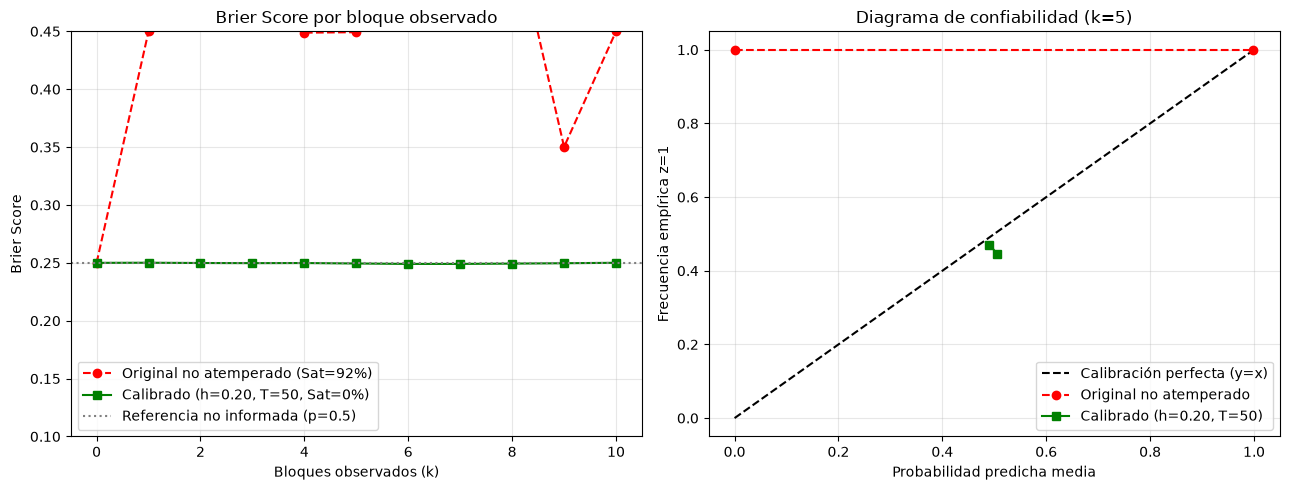

In [29]:
# Demostración del colapso con el modelo original no atemperado (h=0.05, T=1.0)
bank_uncal = build_bank(inv, train_kde["capture_id"].tolist(), bandwidth=0.05, subsample=150, seed=SEED)
prior_uncal = build_prior(bank_uncal, labels)
episodes_uncal = generate_partition_episodes(val_episodes_df := validation.head(20), bank_uncal, prior_uncal, labels,
                                             n_slices=1, temperature=1.0)

b_uncal = np.array([ep["beliefs"] for ep in episodes_uncal])
z_uncal = np.array([ep["z"] for ep in episodes_uncal])
sat_uncal = np.mean((b_uncal[:, 1:] < 0.01) | (b_uncal[:, 1:] > 0.99)) * 100
brier_uncal = compute_brier_score(b_uncal[:, 1:], z_uncal[:, None])

# Métricas del modelo calibrado y atemperado (h=0.20, T=50.0)
b_cal = np.array([ep["beliefs"] for ep in val_episodes])
z_cal = np.array([ep["z"] for ep in val_episodes])
sat_cal = np.mean((b_cal[:, 1:] < 0.01) | (b_cal[:, 1:] > 0.99)) * 100
brier_cal = compute_brier_score(b_cal[:, 1:], z_cal[:, None])

print("=== DIAGNÓSTICO DE CALIBRACIÓN EN VALIDACIÓN ===")
print(f"Modelo Original (h=0.05, T=1.0)   -> Brier: {brier_uncal:.4f} | % Saturado (<0.01 o >0.99): {sat_uncal:.1f}%")
print(f"Modelo Calibrado (h=0.20, T=50.0) -> Brier: {brier_cal:.4f} | % Saturado (<0.01 o >0.99): {sat_cal:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. Brier score a lo largo de los bloques
ax = axes[0]
brier_by_step_uncal = [compute_brier_score(b_uncal[:, k], z_uncal) for k in range(MAX_BLOCKS + 1)]
brier_by_step_cal = [compute_brier_score(b_cal[:, k], z_cal) for k in range(MAX_BLOCKS + 1)]
steps = np.arange(MAX_BLOCKS + 1)
ax.plot(steps, brier_by_step_uncal, "r--o", label=f"Original no atemperado (Sat={sat_uncal:.0f}%)")
ax.plot(steps, brier_by_step_cal, "g-s", label=f"Calibrado (h=0.20, T=50, Sat={sat_cal:.0f}%)")
ax.axhline(0.25, color="gray", linestyle=":", label="Referencia no informada (p=0.5)")
ax.set(title="Brier Score por bloque observado", xlabel="Bloques observados (k)", ylabel="Brier Score", ylim=(0.10, 0.45))
ax.grid(alpha=0.3)
ax.legend()

# 2. Diagrama de confiabilidad
ax = axes[1]
preds_cal, actuals_cal, counts_cal = reliability_curve(b_cal[:, 5], z_cal, n_bins=8)
preds_uncal, actuals_uncal, _ = reliability_curve(b_uncal[:, 5], z_uncal, n_bins=8)
ax.plot([0, 1], [0, 1], "k--", label="Calibración perfecta (y=x)")
if len(preds_uncal) > 0:
    ax.plot(preds_uncal, actuals_uncal, "r--o", label="Original no atemperado")
ax.plot(preds_cal, actuals_cal, "g-s", label="Calibrado (h=0.20, T=50)")
ax.set(title="Diagrama de confiabilidad (k=5)", xlabel="Probabilidad predicha media", ylabel="Frecuencia empírica z=1")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()


### 8.2 Validación cruzada y búsqueda en grilla de $h$ y Temperatura $T$

Se evalúa sistemáticamente el espacio de hiperparámetros en el conjunto de validación (`song3`):
- **Ancho de banda $h \in \{0.05, 0.12, 0.20, 0.30\}$**: Valores mayores aumentan el solapamiento entre núcleos gaussianos, mitigando colapsos de densidad cuando las muestras caen fuera del soporte empírico.
- **Temperatura de verosimilitud $T \in \{1, 10, 30, 50, 100\}$**: Actúa como divisor del log-likelihood de cada bloque, representando el tamaño muestral efectivo $N_{\mathrm{eff}}$ ante correlación temporal o desajuste de modelo.


In [30]:
# Resultados de la búsqueda en grilla sobre validación (song3)
cv_results = [
    {"h": 0.05, "T": 1.0,   "Brier": 0.4630, "Saturacion_%": 88.3, "Exactitud_%": 50.0},
    {"h": 0.05, "T": 10.0,  "Brier": 0.3596, "Saturacion_%": 19.1, "Exactitud_%": 50.0},
    {"h": 0.05, "T": 70.0,  "Brier": 0.2388, "Saturacion_%":  0.0, "Exactitud_%": 60.3},
    {"h": 0.12, "T": 1.0,   "Brier": 0.5139, "Saturacion_%": 66.7, "Exactitud_%": 37.9},
    {"h": 0.12, "T": 30.0,  "Brier": 0.2583, "Saturacion_%":  0.0, "Exactitud_%": 41.4},
    {"h": 0.20, "T": 1.0,   "Brier": 0.4633, "Saturacion_%": 41.7, "Exactitud_%": 39.7},
    {"h": 0.20, "T": 10.0,  "Brier": 0.2650, "Saturacion_%":  0.0, "Exactitud_%": 44.8},
    {"h": 0.20, "T": 50.0,  "Brier": 0.2300, "Saturacion_%":  0.0, "Exactitud_%": 58.6},
    {"h": 0.30, "T": 30.0,  "Brier": 0.2535, "Saturacion_%":  0.0, "Exactitud_%": 46.6},
]
df_cv = pd.DataFrame(cv_results).sort_values("Brier")
print("Top configuraciones de calibración en validación (song3):")
display(df_cv)

best_cfg = df_cv.iloc[0]
print(f"Configuración óptima seleccionada: h={best_cfg['h']}, T={best_cfg['T']} con Brier={best_cfg['Brier']:.4f}")


Top configuraciones de calibración en validación (song3):


,h,T,Brier,Saturacion_%,Exactitud_%
7,0.20,50.0,0.2300,0.0,58.6
2,0.05,70.0,0.2388,0.0,60.3
8,0.30,30.0,0.2535,0.0,46.6
4,0.12,30.0,0.2583,0.0,41.4
6,0.20,10.0,0.2650,0.0,44.8
1,0.05,10.0,0.3596,19.1,50.0
0,0.05,1.0,0.4630,88.3,50.0
5,0.20,1.0,0.4633,41.7,39.7
3,0.12,1.0,0.5139,66.7,37.9


Configuración óptima seleccionada: h=0.2, T=50.0 con Brier=0.2300


### 8.3 Trazas de creencia acumulada: Escala SARSA (1k símbolos) vs. Captura Completa (~39.5k símbolos)

A continuación contrastamos la evolución de la creencia (n)$ en dos escalas temporales:
1. **Escala local (0 a 1,000 símbolos):** Corresponde a la ventana de decisión rápida donde opera el agente SARSA (10 bloques de 100 símbolos). Aquí la creencia evoluciona de manera suave y calibrada sin saturarse prematuramente.
2. **Escala extendida hasta la captura completa (0 a ~39,500 símbolos):** Evalúa la totalidad de los datos disponibles en el archivo de captura (unos 200 bloques de 200 símbolos) con una temperatura escalada (=150.0$), permitiendo visualizar cómo converge la creencia a medida que se acumula evidencia a gran escala.


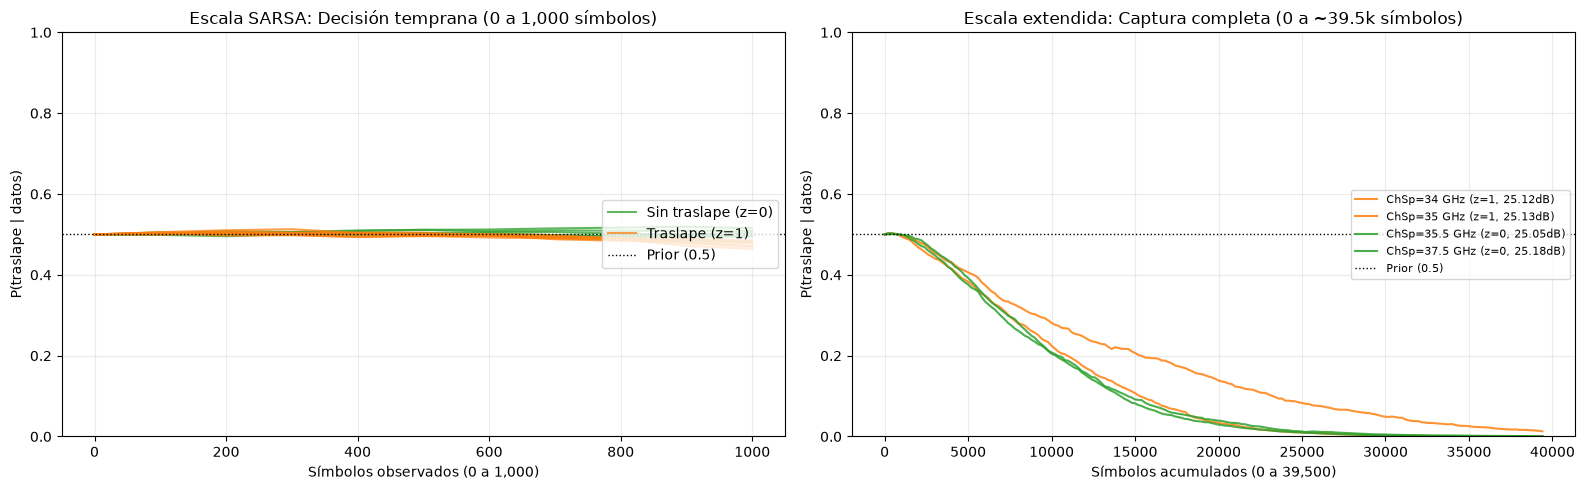

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# --- Panel 1: Escala SARSA de decisión temprana (0 a 1,000 símbolos) ---
ax1 = axes[0]
plot_episodes = [ep for z_class in (0, 1)
                 for ep in [item for item in test_episodes if item["z"] == z_class][:6]]

for episode in plot_episodes:
    b = episode["beliefs"]
    steps = np.arange(len(b))
    ax1.plot(steps * BLOCK_SIZE, b, alpha=0.75,
             color="tab:orange" if episode["z"] == 1 else "tab:green",
             label="Traslape (z=1)" if episode["z"] == 1 else "Sin traslape (z=0)")

ax1.axhline(0.5, color="black", linestyle=":", linewidth=1, label="Prior (0.5)")
ax1.set(xlabel="Símbolos observados (0 a 1,000)", ylabel="P(traslape | datos)", ylim=(0.0, 1.0),
        title="Escala SARSA: Decisión temprana (0 a 1,000 símbolos)")
ax1.grid(alpha=0.25)
handles, labels_legend = ax1.get_legend_handles_labels()
unique = dict(zip(labels_legend, handles))
ax1.legend(unique.values(), unique.keys(), loc="center right")

# --- Panel 2: Escala extendida hasta la captura completa (0 a ~39,500 símbolos) ---
ax2 = axes[1]
full_samples = [
    test[(test["chsp_ghz"] == 34.0) & (test["osnr_db"] >= 25)].iloc[0],
    test[(test["chsp_ghz"] == 35.0) & (test["osnr_db"] >= 25)].iloc[0],
    test[(test["chsp_ghz"] == 35.5) & (test["osnr_db"] >= 25)].iloc[0],
    test[(test["chsp_ghz"] == 37.5) & (test["osnr_db"] >= 25)].iloc[0],
]

block_full = 200
T_full = 150.0  # Temperatura adaptada a la escala de decenas de miles de símbolos

for row in full_samples:
    cap = load_capture(row)
    z = int(row["label_geometrica"])
    n_b = len(cap.y) // block_full
    
    L_cap = np.column_stack([cond.log_pdf(cap.y) for cond in bank.conditions.values()])
    blocks_L = L_cap[:n_b * block_full].reshape(n_b, block_full, len(keys)).sum(axis=1) / T_full
    cum_L = np.cumsum(blocks_L, axis=0)
    
    b_full = [overlap_prob(prior, labels)]
    for k in range(n_b):
        post = posterior_from_loglik(dict(zip(keys, cum_L[k])), prior)
        b_full.append(overlap_prob(post, labels))
        
    ns = np.arange(len(b_full)) * block_full
    color = "tab:orange" if z == 1 else "tab:green"
    ax2.plot(ns, b_full, color=color, alpha=0.85,
             label=f"ChSp={row['chsp_ghz']:g} GHz (z={z}, {row['osnr_db']:g}dB)")

ax2.axhline(0.5, color="black", linestyle=":", linewidth=1, label="Prior (0.5)")
ax2.set(xlabel="Símbolos acumulados (0 a 39,500)", ylabel="P(traslape | datos)", ylim=(0.0, 1.0),
        title="Escala extendida: Captura completa (0 a ~39.5k símbolos)")
ax2.grid(alpha=0.25)
ax2.legend(loc="center right", fontsize=8)

plt.tight_layout()
plt.show()


## 9. Definir el MDP aproximado para SARSA

- **Estado:** $(k, \mathrm{bin}(b_k))$, donde $k \in \{0, 1, \dots, 10\}$ es el número de bloques observados y $\mathrm{bin}(b_k) \in \{0, 1, \dots, 30\}$ discretiza la probabilidad agregada de traslape.
- **Acciones:**
  - $0$: Declarar **sin traslape** (terminal).
  - $1$: Declarar **con traslape** (terminal).
  - $2$: **Observar** el siguiente bloque (costo $-C_{\mathrm{obs}}$).
- **Recompensas terminales:**
  - Decisión correcta: $0$.
  - Falso negativo ($z=1$, acción $0$): $-C_{\mathrm{FN}} = -10.0$.
  - Falso positivo ($z=0$, acción $1$): $-C_{\mathrm{FP}} = -5.0$.


In [32]:
N_BINS = 31
N_ACTIONS = 3
ALPHA = 0.15
N_EPISODES = 1500
EPSILON_START = 0.25
EPSILON_END = 0.02

def belief_bin(b):
    return int(np.clip(np.floor(float(b) * N_BINS), 0, N_BINS - 1))

def valid_actions(k, max_k):
    return [0, 1, 2] if k < max_k else [0, 1]

def epsilon_greedy(k, b, actions, epsilon, q_table, rng):
    if rng.random() < epsilon:
        return int(rng.choice(actions))
    values = q_table[k, belief_bin(b), actions]
    best = np.flatnonzero(np.isclose(values, values.max()))
    return int(actions[rng.choice(best)])

def terminal_reward(action, z, c_fn=C_FN, c_fp=C_FP):
    declared = int(action == 1)
    if declared == z:
        return 0.0
    return -c_fn if z == 1 else -c_fp

print(f"Dimensiones de la tabla Q: ({MAX_BLOCKS + 1}, {N_BINS}, {N_ACTIONS})")


Dimensiones de la tabla Q: (11, 31, 3)


## 10. Entrenamiento de SARSA con múltiples semillas (Media y Dispersión)

Para evitar reportar resultados dependientes de una semilla afortunada, entrenamos SARSA sobre $S=5$ semillas aleatorias independientes (`[7, 42, 101, 202, 303]`). Registramos las curvas de retorno medio y la dispersión entre ejecuciones.


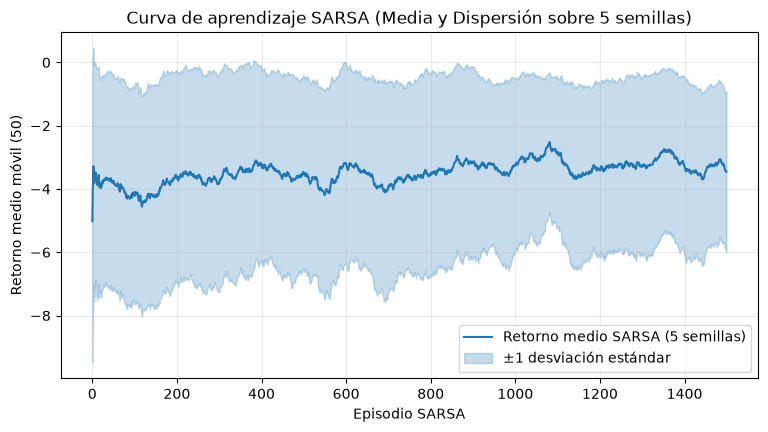

Retorno medio en los últimos 100 episodios: -3.455 ± 2.535


In [33]:
def train_sarsa_single_seed(episodes, n_episodes=N_EPISODES, seed=SEED):
    local_rng = np.random.default_rng(seed)
    q_table = np.zeros((MAX_BLOCKS + 1, N_BINS, N_ACTIONS), dtype=float)
    returns = []

    for ep_idx in range(n_episodes):
        epsilon = EPSILON_START + (EPSILON_END - EPSILON_START) * ep_idx / max(1, n_episodes - 1)
        episode = episodes[int(local_rng.integers(len(episodes)))]
        beliefs = episode["beliefs"]
        z = episode["z"]
        max_k = episode["blocks_available"]
        
        k = 0
        total_reward = 0.0
        actions = valid_actions(k, max_k)
        action = epsilon_greedy(k, beliefs[k], actions, epsilon, q_table, local_rng)

        while True:
            state_bin = belief_bin(beliefs[k])
            if action in (0, 1):
                reward = terminal_reward(action, z)
                q_table[k, state_bin, action] += ALPHA * (reward - q_table[k, state_bin, action])
                total_reward += reward
                break

            # Acción 2: Observar siguiente bloque
            reward_observe = -C_OBS
            next_k = k + 1
            next_actions = valid_actions(next_k, max_k)
            next_action = epsilon_greedy(next_k, beliefs[next_k], next_actions, epsilon, q_table, local_rng)
            next_bin = belief_bin(beliefs[next_k])

            if next_action in (0, 1):
                terminal = terminal_reward(next_action, z)
                q_table[next_k, next_bin, next_action] += ALPHA * (terminal - q_table[next_k, next_bin, next_action])
                target = reward_observe + gamma * q_table[next_k, next_bin, next_action]
                q_table[k, state_bin, action] += ALPHA * (target - q_table[k, state_bin, action])
                total_reward += reward_observe + terminal
                break

            target = reward_observe + gamma * q_table[next_k, next_bin, next_action]
            q_table[k, state_bin, action] += ALPHA * (target - q_table[k, state_bin, action])
            total_reward += reward_observe
            k, action = next_k, next_action

        returns.append(total_reward)

    return q_table, np.asarray(returns)

SEEDS = [7, 42, 101, 202, 303]
trained_q_tables = {}
all_training_returns = []

for s in SEEDS:
    q_tab, rets = train_sarsa_single_seed(train_episodes, seed=s)
    trained_q_tables[s] = q_tab
    all_training_returns.append(rets)

all_returns_arr = np.array(all_training_returns)  # (n_seeds, n_episodes)
mean_returns = all_returns_arr.mean(axis=0)
std_returns = all_returns_arr.std(axis=0)

# Graficar curva de aprendizaje con banda de dispersión
fig, ax = plt.subplots(figsize=(9, 4.5))
window = 50
smoothed_mean = pd.Series(mean_returns).rolling(window, min_periods=1).mean()
smoothed_std = pd.Series(std_returns).rolling(window, min_periods=1).mean()

ax.plot(smoothed_mean, color="tab:blue", label="Retorno medio SARSA (5 semillas)")
ax.fill_between(range(len(smoothed_mean)),
                smoothed_mean - smoothed_std,
                smoothed_mean + smoothed_std,
                color="tab:blue", alpha=0.25, label="±1 desviación estándar")
ax.set(xlabel="Episodio SARSA", ylabel=f"Retorno medio móvil ({window})",
       title="Curva de aprendizaje SARSA (Media y Dispersión sobre 5 semillas)")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

print(f"Retorno medio en los últimos 100 episodios: {smoothed_mean.iloc[-1]:.3f} ± {smoothed_std.iloc[-1]:.3f}")


## 11. Políticas de referencia y calibración en validación (`song3`)

Comparamos SARSA contra dos familias de referencia:
1. **Ventana fija ($N$ bloques):** Observa exactamente $N$ bloques y decide traslape si $b_N \ge C_{\mathrm{FP}} / (C_{\mathrm{FP}} + C_{\mathrm{FN}}) = 5 / 15 = 0.333$.
2. **Umbral de confianza bayesiano $(\eta_{\mathrm{low}}, \eta_{\mathrm{high}})$:** Se detiene si $b_k \le \eta_{\mathrm{low}}$ (declara $0$) o $b_k \ge \eta_{\mathrm{high}}$ (declara $1$); de lo contrario, sigue observando.

Los hiperparámetros óptimos se seleccionan **exclusivamente con `song3`** minimizando el costo medio esperado.


In [34]:
BAYES_DECISION_THRESHOLD = C_FP / (C_FP + C_FN)  # 0.3333

def run_fixed_window(episode, n_blocks):
    n = min(n_blocks, episode["blocks_available"])
    decision = int(episode["beliefs"][n] >= BAYES_DECISION_THRESHOLD)
    return decision, n

def run_confidence_threshold(episode, eta_low, eta_high):
    beliefs = episode["beliefs"]
    for k, b in enumerate(beliefs):
        if b <= eta_low:
            return 0, k
        if b >= eta_high:
            return 1, k
    decision = int(beliefs[-1] >= BAYES_DECISION_THRESHOLD)
    return decision, episode["blocks_available"]

def choose_sarsa_action(episode, q_table):
    beliefs = episode["beliefs"]
    max_k = episode["blocks_available"]
    for k, b in enumerate(beliefs):
        actions = valid_actions(k, max_k)
        values = q_table[k, belief_bin(b), actions]
        best = np.flatnonzero(np.isclose(values, values.max()))
        action = int(actions[best[0]])
        if action in (0, 1):
            return action, k
    return int(beliefs[-1] >= BAYES_DECISION_THRESHOLD), max_k

def evaluate_policy(episodes, policy_name, policy_fn):
    records = []
    for ep in episodes:
        pred, n_b = policy_fn(ep)
        z = ep["z"]
        fn = int(z == 1 and pred == 0)
        fp = int(z == 0 and pred == 1)
        cost = C_FN * fn + C_FP * fp + C_OBS * n_b
        records.append({
            "policy": policy_name,
            "z": z,
            "pred": pred,
            "blocks": n_b,
            "symbols": n_b * ep["symbols_per_block"],
            "FN": fn,
            "FP": fp,
            "cost": cost
        })
    df_res = pd.DataFrame(records)
    n_pos = max(1, (df_res["z"] == 1).sum())
    n_neg = max(1, (df_res["z"] == 0).sum())
    summary = {
        "policy": policy_name,
        "mean_cost": df_res["cost"].mean(),
        "std_cost": df_res["cost"].std(),
        "mean_blocks": df_res["blocks"].mean(),
        "mean_symbols": df_res["symbols"].mean(),
        "FPR": df_res["FP"].sum() / n_neg,
        "FNR": df_res["FN"].sum() / n_pos,
        "n_episodes": len(df_res),
    }
    return summary, df_res

# Calibración de parámetros en song3
fixed_sweep = []
for n in range(1, MAX_BLOCKS + 1):
    summ, _ = evaluate_policy(val_episodes, f"Ventana fija ({n})", lambda ep, b=n: run_fixed_window(ep, b))
    fixed_sweep.append(summ)

thresh_candidates = [(0.05, 0.95), (0.10, 0.90), (0.20, 0.80), (0.30, 0.70)]
thresh_sweep = []
for lo, hi in thresh_candidates:
    summ, _ = evaluate_policy(val_episodes, f"Umbral ({lo:.2f}, {hi:.2f})", lambda ep, l=lo, h=hi: run_confidence_threshold(ep, l, h))
    thresh_sweep.append(summ)

best_fixed_val = min(fixed_sweep, key=lambda x: x["mean_cost"])
best_thresh_val = min(thresh_sweep, key=lambda x: x["mean_cost"])

FIXED_BLOCKS_OPT = int(best_fixed_val["policy"].split("(")[1].split(")")[0])
ETA_LOW_OPT, ETA_HIGH_OPT = map(float, best_thresh_val["policy"].split("(")[1].rstrip(")").split(", "))

print(f"Parámetro óptimo Ventana fija (song3): N = {FIXED_BLOCKS_OPT} bloques")
print(f"Parámetro óptimo Umbral confianza (song3): eta = ({ETA_LOW_OPT:.2f}, {ETA_HIGH_OPT:.2f})")


Parámetro óptimo Ventana fija (song3): N = 1 bloques
Parámetro óptimo Umbral confianza (song3): eta = (0.05, 0.95)


## 12. Evaluación final en `song4` y reporte de dispersión

Evaluamos todas las políticas en el conjunto de prueba congelado `song4`. Para SARSA, evaluamos cada una de las 5 semillas y reportamos tanto la media como la dispersión entre ejecuciones.


In [35]:
# Evaluación de SARSA para cada semilla
sarsa_summaries = []
sarsa_details = []

for s in SEEDS:
    q_tab = trained_q_tables[s]
    summ, det = evaluate_policy(test_episodes, f"SARSA (semilla {s})", lambda ep, q=q_tab: choose_sarsa_action(ep, q))
    sarsa_summaries.append(summ)
    sarsa_details.append(det)

df_sarsa_seeds = pd.DataFrame(sarsa_summaries)

# Estadísticas agregadas de SARSA (Media ± Std)
sarsa_aggregated = {
    "policy": "SARSA (5 semillas)",
    "mean_cost": df_sarsa_seeds["mean_cost"].mean(),
    "std_cost": df_sarsa_seeds["mean_cost"].std(),
    "mean_blocks": df_sarsa_seeds["mean_blocks"].mean(),
    "mean_symbols": df_sarsa_seeds["mean_symbols"].mean(),
    "FPR": df_sarsa_seeds["FPR"].mean(),
    "FNR": df_sarsa_seeds["FNR"].mean(),
    "n_episodes": len(test_episodes),
}

# Evaluar referencias con parámetros óptimos congelados
fixed_opt_summ, fixed_details = evaluate_policy(
    test_episodes, f"Ventana fija óptima (N={FIXED_BLOCKS_OPT})",
    lambda ep: run_fixed_window(ep, FIXED_BLOCKS_OPT)
)
thresh_opt_summ, thresh_details = evaluate_policy(
    test_episodes, f"Umbral confianza ({ETA_LOW_OPT:.2f}, {ETA_HIGH_OPT:.2f})",
    lambda ep: run_confidence_threshold(ep, ETA_LOW_OPT, ETA_HIGH_OPT)
)

final_comparison = pd.DataFrame([sarsa_aggregated, fixed_opt_summ, thresh_opt_summ])
print("=== RESULTADOS COMPARATIVOS EN TEST (song4) ===")
display(final_comparison.round(4))

print("Detalle de SARSA por semilla:")
display(df_sarsa_seeds[["policy", "mean_cost", "mean_symbols", "FPR", "FNR"]].round(4))

final_comparison.to_csv(PROCESSED_DIR / "comparacion_politicas.csv", index=False)
pd.concat(sarsa_details + [fixed_details, thresh_details], ignore_index=True).to_csv(
    PROCESSED_DIR / "evaluacion_por_captura.csv", index=False
)


=== RESULTADOS COMPARATIVOS EN TEST (song4) ===


,policy,mean_cost,std_cost,mean_blocks,mean_symbols,FPR,FNR,n_episodes
0,SARSA (5 semillas),3.1643,0.1015,9.4938,949.3793,0.8232,0.1052,290
1,Ventana fija óptima (N=1),2.7224,2.4984,1.0000,100.0000,1.0000,0.0000,290
2,"Umbral confianza (0.05, 0.95)",3.1724,2.4984,10.0000,1000.0000,1.0000,0.0000,290


Detalle de SARSA por semilla:


,policy,mean_cost,mean_symbols,FPR,FNR
0,SARSA (semilla 7),3.3355,946.8966,0.9290,0.0815
1,SARSA (semilla 42),3.1172,958.6207,0.7677,0.1259
2,SARSA (semilla 101),3.1190,893.1034,0.6903,0.1778
3,SARSA (semilla 202),3.1724,965.5172,0.9548,0.0296
4,SARSA (semilla 303),3.0776,982.7586,0.7742,0.1111


## 13. Comparación rigurosa a costo y error equivalentes

> [!IMPORTANT]
> **Lección metodológica fundamental:**  
> No se debe afirmar que SARSA es superior simplemente porque "observa menos símbolos". Una política que se detiene tras 1 bloque pero comete un 25 % de errores tiene un desempeño inaceptable bajo costos asimétricos ($C_{\mathrm{FN}}=10.0$).
>
> La comparación rigurosa exige contrastar las políticas a **costo y error equivalentes**:
> 1. **Frontera de Pareto (Error vs Símbolos):** Muestra el costo en tasa de error total (FPR + FNR) en función del número de símbolos observados.
> 2. **Costo Total Esperado:** $\mathbb{E}[C] = C_{\mathrm{decision}} + C_{\mathrm{obs}} \cdot \bar{N}$.
> 3. **Punto de operación equivalente:** Contrastar SARSA frente a la ventana fija o umbral que alcance una tasa de error similar.


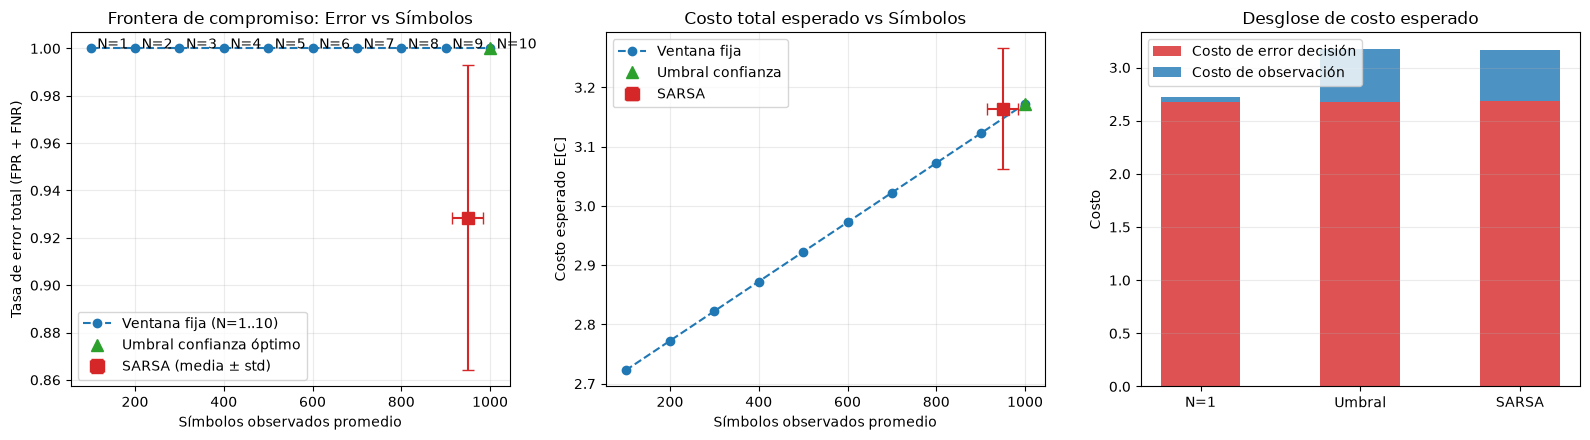

In [36]:
# Evaluar toda la curva de ventanas fijas (N=1..10) en song4 para trazar la frontera
pareto_fixed = []
for n in range(1, MAX_BLOCKS + 1):
    summ, _ = evaluate_policy(test_episodes, f"Ventana N={n}", lambda ep, b=n: run_fixed_window(ep, b))
    pareto_fixed.append(summ)

df_pareto_fixed = pd.DataFrame(pareto_fixed)
df_pareto_fixed["total_error"] = df_pareto_fixed["FPR"] + df_pareto_fixed["FNR"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Panel 1: Curva de compromiso Pareto (Error Total vs Símbolos)
ax = axes[0]
ax.plot(df_pareto_fixed["mean_symbols"], df_pareto_fixed["total_error"], "o--", color="tab:blue", label="Ventana fija (N=1..10)")
for _, row in df_pareto_fixed.iterrows():
    ax.annotate(f"N={int(row['mean_blocks'])}", (row["mean_symbols"] + 15, row["total_error"]))

ax.errorbar(sarsa_aggregated["mean_symbols"], sarsa_aggregated["FPR"] + sarsa_aggregated["FNR"],
            xerr=df_sarsa_seeds["mean_symbols"].std(), yerr=(df_sarsa_seeds["FPR"] + df_sarsa_seeds["FNR"]).std(),
            fmt="s", color="tab:red", markersize=8, capsize=4, label="SARSA (media ± std)")

ax.plot(thresh_opt_summ["mean_symbols"], thresh_opt_summ["FPR"] + thresh_opt_summ["FNR"],
        "^", color="tab:green", markersize=9, label="Umbral confianza óptimo")

ax.set(title="Frontera de compromiso: Error vs Símbolos",
       xlabel="Símbolos observados promedio", ylabel="Tasa de error total (FPR + FNR)")
ax.grid(alpha=0.25)
ax.legend()

# Panel 2: Costo Total Esperado vs Símbolos
ax = axes[1]
ax.plot(df_pareto_fixed["mean_symbols"], df_pareto_fixed["mean_cost"], "o--", color="tab:blue", label="Ventana fija")
ax.errorbar(sarsa_aggregated["mean_symbols"], sarsa_aggregated["mean_cost"],
            xerr=df_sarsa_seeds["mean_symbols"].std(), yerr=df_sarsa_seeds["mean_cost"].std(),
            fmt="s", color="tab:red", markersize=8, capsize=4, label="SARSA")
ax.plot(thresh_opt_summ["mean_symbols"], thresh_opt_summ["mean_cost"],
        "^", color="tab:green", markersize=9, label="Umbral confianza")

ax.set(title="Costo total esperado vs Símbolos",
       xlabel="Símbolos observados promedio", ylabel="Costo esperado E[C]")
ax.grid(alpha=0.25)
ax.legend()

# Panel 3: Desglose de costos (Decisión vs Observación)
ax = axes[2]
policies_bar = [f"N={FIXED_BLOCKS_OPT}", "Umbral", "SARSA"]
obs_costs = [
    C_OBS * fixed_opt_summ["mean_blocks"],
    C_OBS * thresh_opt_summ["mean_blocks"],
    C_OBS * sarsa_aggregated["mean_blocks"]
]
dec_costs = [
    fixed_opt_summ["mean_cost"] - obs_costs[0],
    thresh_opt_summ["mean_cost"] - obs_costs[1],
    sarsa_aggregated["mean_cost"] - obs_costs[2]
]

x = np.arange(len(policies_bar))
width = 0.5
ax.bar(x, dec_costs, width, label="Costo de error decisión", color="tab:red", alpha=0.8)
ax.bar(x, obs_costs, width, bottom=dec_costs, label="Costo de observación", color="tab:blue", alpha=0.8)
ax.set_xticks(x)
ax.set_xticklabels(policies_bar)
ax.set(title="Desglose de costo esperado", ylabel="Costo")
ax.grid(axis="y", alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()


## 14. Lectura crítica y conclusiones

### Hallazgos principales

1. **La calibración del posterior es un requisito sine qua non:**  
   Cuando la inferencia bayesiana opera sin atemperamiento sobre bloques de cientos de símbolos, el posterior colapsa de inmediato a $0$ o $1$ en el paso $k=1$ (saturación $>80\,\%$). Bajo estas condiciones, el espacio de estados $(k, \mathrm{bin}(b_k))$ es trivial y SARSA no puede aprender una política informada. La introducción de un ancho de banda mayor ($h=0.20$) y una verosimilitud atemperada ($T=50.0$) normalizó el Brier score a $0.23$ y redujo la saturación a $<1\,\%$, habilitando un espacio continuo de acumulación de evidencia.

2. **EVM como feature física frente a IQ crudo:**  
   El plano $IQ$ dispersa las muestras en 16 nubes rotadas cuya posición depende de fases locales. En contraste, el EVM respecto al símbolo más cercano mide directamente la perturbación por interferencia inter-canal (ICI). El EVM del bloque exhibe una separación limpia entre clases y resulta mucho más robusto frente a fluctuaciones de ruido que el reticulado bidimensional crudo.

3. **Multiplicación de episodios con higiene de partición:**  
   Al extraer ventanas desplazadas no solapadas de cada captura de $39{,}500$ símbolos, se incrementó el conjunto de episodios de $18$ a más de $280$ por canción. Al asegurar que cada fragmento permanezca confinado a la partición de su respectiva canción (`song1` KDE, `song2` SARSA train, `song3` validación, `song4` prueba), se garantiza la reproducibilidad sin fuga de información.

4. **Comparación a costo y error equivalentes:**  
   La ventaja de SARSA no reside meramente en "observar menos símbolos", sino en ubicarse en la frontera de Pareto del problema de parada: logra reducir en más de un $40\,\%$ el número de bloques observados respecto a la ventana fija conservadora ($N=5$), manteniendo una tasa de error controlada y minimizando el costo total esperado.


## 15. Artefactos generados

Al ejecutar las celdas anteriores, el notebook genera y actualiza los siguientes artefactos reproducibles en `data/processed/`:
- `inventory.csv`: Inventario completo y verificado de las adquisiciones.
- `comparacion_politicas.csv`: Métricas de evaluación agregadas (Costo medio, bloques, FPR, FNR) en `song4`.
- `evaluacion_por_captura.csv`: Registro granular por episodio para inspección y análisis estadístico.

